# Concept Bottleneck Models for Interpretable ECG Diagnosis — 03: CBM, interventions & interpretability

Predictions are forced through a layer of clinical ECG concepts (form and rhythm findings) before the diagnosis:
**x → ĉ (concepts) → ŷ (5 superclasses)**, with a *linear* concept → diagnosis head so its weights are interpretable.

Three training schemes (Koh et al., 2020), all with the **same encoder and random-crop protocol as the black-box baseline**:
- **Independent:** x→c trained on concepts; c→y trained on *true* concepts.
- **Sequential:** x→c trained on concepts; c→y trained on the *predicted* concepts.
- **Joint:** x→c→y trained end to end, loss = L_y + λ·L_c (λ = 1).

**Experiments:** (E1) task and concept performance vs. black-box, with paired bootstrap; (E2) test-time concept interventions (random vs. uncertainty-based order); (E3) clinical plausibility of the concept → diagnosis weights.

**Pre-registered hypothesis (notebook 01):** the CBM loses most on **CD**, then **STTC**, because the concept set barely covers conduction disorders.

## 1. Setup
Locates the outputs of notebooks 01 (signals, labels) and 02 (black-box test probabilities, normalization stats) and the PTB-XL statement table.

In [2]:
import glob, random, time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from sklearn.metrics import roc_auc_score

def find(name):
    hits = glob.glob(f"/kaggle/input/**/{name}", recursive=True)
    assert hits, f"{name} not found: add the corresponding input via '+ Add Input'"
    return Path(hits[0]).parent

IN0, IN1, IN2 = find("scp_statements.csv"), find("X100.npy"), find("blackbox_crop_test_probs.npy")
OUT = Path("/kaggle/working")
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
AMP = DEVICE.type == "cuda"
SUPER = ["NORM", "MI", "STTC", "CD", "HYP"]
SEEDS = [0, 1, 2, 3, 4]
WIN, STRIDE = 250, 125  # 2.5 s crops / 1.25 s stride, identical to the black-box baseline

def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)

print("IN1:", IN1, "\nIN2:", IN2, "\ndevice:", DEVICE)

IN1: /kaggle/input/notebooks/antonioboza/ptbxl-cbm-01-data-and-concepts 
IN2: /kaggle/input/notebooks/antonioboza/ptbxl-cbm-02-blackbox-baseline 
device: cuda


## 2. Data, concepts and splits
Same folds and the **same normalization statistics** as the black-box (loaded from notebook 02). Concepts are selected using **training-set counts only** (≥ 40 positives, equivalent to the ≥ 50 overall threshold of the EDA), so the test set plays no role in the choice.

In [3]:
X = np.load(IN1 / "X100.npy", mmap_mode="r")
L = np.load(IN1 / "labels.npz")
Y, C, has_y, fold = L["Y"], L["C"], L["has_y"], L["fold"]
CONCEPTS_ALL = pd.read_csv(IN1 / "concepts.csv")["concept"].tolist()
scp = pd.read_csv(IN0 / "scp_statements.csv", index_col=0)

idx = {"train": np.where(has_y & (fold <= 8))[0],
       "val":   np.where(has_y & (fold == 9))[0],
       "test":  np.where(has_y & (fold == 10))[0]}

keep = np.where(C[idx["train"]].sum(0) >= 40)[0]
CONCEPTS = [CONCEPTS_ALL[i] for i in keep]; K = len(CONCEPTS)
CTYPE = ["form" if scp.loc[c, "form"] == 1 else "rhythm" for c in CONCEPTS]
print(f"{K} concepts:", list(zip(CONCEPTS, CTYPE)))

S = np.load(IN2 / "norm_stats.npz"); mu, sd = S["mu"], S["sd"]
def prep(ii):
    return ((np.asarray(X[ii]) - mu) / sd).astype(np.float32).transpose(0, 2, 1).copy()

data = {k: (torch.from_numpy(prep(v)),
            torch.from_numpy(Y[v].astype(np.float32)),
            torch.from_numpy(C[v][:, keep].astype(np.float32))) for k, v in idx.items()}
(Xtr, Ytr, Ctr), (Xva, Yva, Cva), (Xte, Yte, Cte) = data["train"], data["val"], data["test"]
ytr, yva, yte = Ytr.numpy(), Yva.numpy(), Yte.numpy()
ctr, cva, cte = Ctr.numpy(), Cva.numpy(), Cte.numpy()
print("test positives per concept:", dict(zip(CONCEPTS, cte.sum(0).astype(int))))

19 concepts: [('ABQRS', 'form'), ('AFIB', 'rhythm'), ('BIGU', 'rhythm'), ('HVOLT', 'form'), ('INVT', 'form'), ('LOWT', 'form'), ('LPR', 'form'), ('LVOLT', 'form'), ('NT_', 'form'), ('PAC', 'form'), ('PVC', 'form'), ('QWAVE', 'form'), ('SARRH', 'rhythm'), ('SBRAD', 'rhythm'), ('SR', 'rhythm'), ('STACH', 'rhythm'), ('STD_', 'form'), ('SVARR', 'rhythm'), ('VCLVH', 'form')]
test positives per concept: {'ABQRS': np.int64(322), 'AFIB': np.int64(144), 'BIGU': np.int64(7), 'HVOLT': np.int64(6), 'INVT': np.int64(29), 'LOWT': np.int64(44), 'LPR': np.int64(34), 'LVOLT': np.int64(18), 'NT_': np.int64(42), 'PAC': np.int64(40), 'PVC': np.int64(113), 'QWAVE': np.int64(55), 'SARRH': np.int64(77), 'SBRAD': np.int64(63), 'SR': np.int64(1673), 'STACH': np.int64(82), 'STD_': np.int64(101), 'SVARR': np.int64(14), 'VCLVH': np.int64(87)}


## 3. Model
Same 1D ResNet encoder as the black-box. The CBM adds a **concept head** (encoder features → K concept logits) and a **linear task head** (K concept probabilities → 5 superclass logits). The diagnosis can only use information that passes through the concepts.

In [4]:
class ResBlock1d(nn.Module):
    def __init__(self, cin, cout, stride, k=9, p_drop=0.1):
        super().__init__()
        self.c1 = nn.Conv1d(cin, cout, k, stride, k // 2, bias=False); self.b1 = nn.BatchNorm1d(cout)
        self.c2 = nn.Conv1d(cout, cout, k, 1, k // 2, bias=False);     self.b2 = nn.BatchNorm1d(cout)
        self.drop = nn.Dropout(p_drop)
        self.skip = (nn.Identity() if cin == cout and stride == 1 else
                     nn.Sequential(nn.Conv1d(cin, cout, 1, stride, bias=False), nn.BatchNorm1d(cout)))
    def forward(self, x):
        h = F.relu(self.b1(self.c1(x)))
        h = self.b2(self.c2(self.drop(h)))
        return F.relu(h + self.skip(x))

class Encoder(nn.Module):
    def __init__(self, cin=12, widths=(64, 128, 192, 256), k=9):
        super().__init__()
        self.stem = nn.Sequential(nn.Conv1d(cin, widths[0], 15, 2, 7, bias=False),
                                  nn.BatchNorm1d(widths[0]), nn.ReLU())
        blocks, c = [], widths[0]
        for w in widths:
            blocks += [ResBlock1d(c, w, stride=2, k=k), ResBlock1d(w, w, stride=1, k=k)]; c = w
        self.blocks = nn.Sequential(*blocks)
        self.out_dim = 2 * c
    def forward(self, x):
        h = self.blocks(self.stem(x))
        return torch.cat([h.mean(-1), h.amax(-1)], dim=1)

class CBM(nn.Module):
    def __init__(self, k, n_out=5, p_drop=0.3):
        super().__init__()
        self.enc = Encoder()
        self.concept_head = nn.Sequential(nn.Dropout(p_drop), nn.Linear(self.enc.out_dim, k))
        self.task_head = nn.Linear(k, n_out)          # linear => interpretable concept weights
    def concepts(self, x):                             # concept logits
        return self.concept_head(self.enc(x))
    def forward(self, x):
        c_logit = self.concepts(x)
        return c_logit, self.task_head(torch.sigmoid(c_logit))

print(f"params: {sum(p.numel() for p in CBM(K).parameters()) / 1e6:.2f} M")

params: 4.21 M


## 4. Training and evaluation functions
- `train_cbm(mode="concept")`: trains x → c only (used by the independent and sequential CBMs). Model selection on **validation macro concept AUROC**.
- `train_cbm(mode="joint")`: trains x → c → y end to end. Model selection on **validation task macro AUROC**.
- `fit_head`: logistic-regression task head c → y (full batch).
- At test time, concept probabilities are averaged over sliding 2.5 s windows, then passed to the task head. This makes test-time interventions identical for all three variants.

In [5]:
def random_crop(xb, win=WIN):
    starts = torch.randint(0, xb.shape[-1] - win + 1, (xb.shape[0],), device=xb.device)
    ii = (starts[:, None] + torch.arange(win, device=xb.device))[:, None, :].expand(-1, xb.shape[1], -1)
    return torch.gather(xb, 2, ii)

def macro_auc(y, p):
    return roc_auc_score(y, p, average="macro")

def macro_auc_safe(y, p):  # skips columns with a single class (rare concepts in small folds)
    cols = [j for j in range(y.shape[1]) if 0 < y[:, j].sum() < len(y)]
    return roc_auc_score(y[:, cols], p[:, cols], average="macro")

@torch.no_grad()
def predict_concepts(model, Xt, bs=512):
    """Window-averaged concept probabilities, shape (N, K)."""
    model.eval(); out = []
    starts = range(0, Xt.shape[-1] - WIN + 1, STRIDE)
    for i in range(0, len(Xt), bs):
        xb = Xt[i:i + bs].to(DEVICE)
        with torch.autocast("cuda", enabled=AMP):
            ps = [torch.sigmoid(model.concepts(xb[:, :, s:s + WIN])).float() for s in starts]
        out.append(torch.stack(ps).mean(0).cpu())
    return torch.cat(out).numpy()

@torch.no_grad()
def head_probs(head, cprobs):
    dev = next(head.parameters()).device
    return torch.sigmoid(head(torch.as_tensor(cprobs, dtype=torch.float32, device=dev))).cpu().numpy()

def train_cbm(seed, mode, lam=1.0, epochs=60, bs=128, lr=1e-3, wd=1e-2, patience=10, verbose=False):
    assert mode in ("concept", "joint")
    set_seed(seed)
    model = CBM(K).to(DEVICE)
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=wd)
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=lr, total_steps=epochs * ((len(Xtr) + bs - 1) // bs))
    scaler = torch.amp.GradScaler("cuda", enabled=AMP)
    g = torch.Generator().manual_seed(seed)
    best, best_state, bad, hist = -1.0, None, 0, []

    for ep in range(epochs):
        model.train(); t0, tot = time.time(), 0.0
        perm = torch.randperm(len(Xtr), generator=g)
        for i in range(0, len(Xtr), bs):
            b = perm[i:i + bs]
            xb = random_crop(Xtr[b].to(DEVICE, non_blocking=True))
            yb, cb = Ytr[b].to(DEVICE), Ctr[b].to(DEVICE)
            with torch.autocast("cuda", enabled=AMP):
                c_logit, y_logit = model(xb)
                loss = F.binary_cross_entropy_with_logits(c_logit, cb)
                if mode == "joint":
                    loss = F.binary_cross_entropy_with_logits(y_logit, yb) + lam * loss
            opt.zero_grad(set_to_none=True)
            scaler.scale(loss).backward(); scaler.step(opt); scaler.update(); sched.step()
            tot += loss.item() * len(b)

        cp_va = predict_concepts(model, Xva)
        va = (macro_auc_safe(cva, cp_va) if mode == "concept"
              else macro_auc_safe(yva, head_probs(model.task_head, cp_va)))
        hist.append({"epoch": ep, "train_loss": tot / len(Xtr), "val_auc": va})
        if va > best:
            best, bad = va, 0
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
        else:
            bad += 1
        if verbose:
            print(f"[{mode}] seed {seed} | ep {ep:02d} | loss {tot / len(Xtr):.4f} | val AUROC {va:.4f} | {time.time() - t0:.1f}s")
        if bad >= patience:
            break

    model.load_state_dict(best_state)
    return model, best, pd.DataFrame(hist)

def fit_head(c_in, y, seed, steps=1000, lr=0.05, wd=1e-4):
    """Logistic-regression head c -> y, full batch."""
    set_seed(seed)
    head = nn.Linear(K, len(SUPER)).to(DEVICE)
    Xc = torch.as_tensor(c_in, dtype=torch.float32, device=DEVICE)
    Yt = torch.as_tensor(y, dtype=torch.float32, device=DEVICE)
    opt = torch.optim.Adam(head.parameters(), lr=lr, weight_decay=wd)
    for _ in range(steps):
        loss = F.binary_cross_entropy_with_logits(head(Xc), Yt)
        opt.zero_grad(); loss.backward(); opt.step()
    return head.eval()

def bootstrap_ci(y, p, n=1000, seed=0):
    rng = np.random.default_rng(seed); b = []
    for _ in range(n):
        ii = rng.integers(0, len(y), len(y))
        if y[ii].sum(0).min() > 0:
            b.append(macro_auc(y[ii], p[ii]))
    return np.percentile(b, [2.5, 97.5])

def paired_delta(y, pa, pb, n=1000, seed=1):
    """Paired bootstrap of macro AUROC(pa) - macro AUROC(pb) on the same resampled records."""
    rng = np.random.default_rng(seed); d = []
    for _ in range(n):
        ii = rng.integers(0, len(y), len(y))
        if y[ii].sum(0).min() > 0:
            d.append(macro_auc(y[ii], pa[ii]) - macro_auc(y[ii], pb[ii]))
    return np.mean(d), *np.percentile(d, [2.5, 97.5])

## 5. Smoke test
Two epochs of each training mode to verify the pipeline before the full run.

In [5]:
_m, _b, _ = train_cbm(0, "concept", epochs=2, verbose=True); print("concept-model val macro concept AUROC:", round(_b, 4))
_m, _b, _ = train_cbm(0, "joint", epochs=2, verbose=True);   print("joint CBM val task AUROC:", round(_b, 4))
del _m; torch.cuda.empty_cache()

[concept] seed 0 | ep 00 | loss 0.2013 | val AUROC 0.7747 | 4.5s
[concept] seed 0 | ep 01 | loss 0.1222 | val AUROC 0.8272 | 2.5s
concept-model val macro concept AUROC: 0.8272
[joint] seed 0 | ep 00 | loss 0.8599 | val AUROC 0.6558 | 2.6s
[joint] seed 0 | ep 01 | loss 0.7465 | val AUROC 0.6836 | 2.6s
joint CBM val task AUROC: 0.6836


## 6. Full experiment (5 seeds × 3 CBM variants)
Per seed: one concept model (shared by independent and sequential, which differ only in how the task head is trained) and one joint model. Saves test concept probabilities, task heads and weights.

In [6]:
store = {v: {"cp_te": [], "heads": [], "val_task": []} for v in ["independent", "sequential", "joint"]}

for s in SEEDS:
    t0 = time.time()
    g, best_c, _ = train_cbm(s, "concept")
    cp_tr, cp_va, cp_te = (predict_concepts(g, X_) for X_ in (Xtr, Xva, Xte))
    for v, c_in in [("independent", ctr), ("sequential", cp_tr)]:
        h = fit_head(c_in, ytr, s).cpu()
        store[v]["cp_te"].append(cp_te); store[v]["heads"].append(h)
        store[v]["val_task"].append(macro_auc(yva, head_probs(h, cp_va)))
    torch.save(g.state_dict(), OUT / f"cbm_concept_seed{s}.pt")

    j, best_j, _ = train_cbm(s, "joint")
    store["joint"]["cp_te"].append(predict_concepts(j, Xte))
    store["joint"]["heads"].append(j.task_head.cpu())
    store["joint"]["val_task"].append(best_j)
    torch.save(j.state_dict(), OUT / f"cbm_joint_seed{s}.pt")

    print(f"seed {s} | concept val AUROC {best_c:.4f} | val task AUROC: "
          f"ind {store['independent']['val_task'][-1]:.4f} · seq {store['sequential']['val_task'][-1]:.4f} · "
          f"joint {best_j:.4f} | {(time.time() - t0) / 60:.1f} min")
    del g, j; torch.cuda.empty_cache()

for v in store:
    np.save(OUT / f"cbm_{v}_test_concept_probs.npy", np.array(store[v]["cp_te"]))
    torch.save([h.state_dict() for h in store[v]["heads"]], OUT / f"cbm_{v}_heads.pt")

seed 0 | concept val AUROC 0.9380 | val task AUROC: ind 0.8206 · seq 0.8298 · joint 0.9210 | 4.9 min
seed 1 | concept val AUROC 0.9374 | val task AUROC: ind 0.8149 · seq 0.8243 · joint 0.9193 | 4.3 min
seed 2 | concept val AUROC 0.9347 | val task AUROC: ind 0.8193 · seq 0.8336 · joint 0.9205 | 4.1 min
seed 3 | concept val AUROC 0.9372 | val task AUROC: ind 0.8208 · seq 0.8304 · joint 0.9192 | 4.4 min
seed 4 | concept val AUROC 0.9390 | val task AUROC: ind 0.8145 · seq 0.8232 · joint 0.9188 | 4.9 min


## 7. E1 — Task performance: CBM vs. black-box
Single-model mean ± std, 5-seed ensemble with bootstrap 95% CI, per-class AUROC, per-class Δ vs. black-box (to test the pre-registered hypothesis) and paired bootstrap of the ensemble difference.

In [7]:
bb_probs = np.load(IN2 / "blackbox_crop_test_probs.npy")
P = {"black-box": bb_probs,
     **{f"CBM-{v}": np.array([head_probs(h, cp) for h, cp in zip(store[v]["heads"], store[v]["cp_te"])])
        for v in store}}

per_class = {m: np.array([roc_auc_score(yte, p, average=None) for p in probs]) for m, probs in P.items()}
rows = []
for m, probs in P.items():
    macro = per_class[m].mean(1); ens = probs.mean(0); lo, hi = bootstrap_ci(yte, ens)
    rows.append({"model": m,
                 "single (mean ± std)": f"{macro.mean():.4f} ± {macro.std(ddof=1):.4f}",
                 "ensemble [95% CI]": f"{macro_auc(yte, ens):.4f} [{lo:.4f}–{hi:.4f}]",
                 **{c: round(per_class[m][:, j].mean(), 4) for j, c in enumerate(SUPER)}})
table1 = pd.DataFrame(rows)
print(table1.to_string(index=False))

print("\nPer-class Δ AUROC vs. black-box (single-model means):")
for m in list(P)[1:]:
    print(f"  {m:16s}", dict(zip(SUPER, np.round(per_class[m].mean(0) - per_class['black-box'].mean(0), 4))))

print("\nPaired bootstrap, ensemble Δ macro AUROC (CBM − black-box):")
for m in list(P)[1:]:
    d, lo, hi = paired_delta(yte, P[m].mean(0), bb_probs.mean(0))
    print(f"  {m:16s} {d:+.4f}  (95% CI {lo:+.4f} to {hi:+.4f})")
table1.to_csv(OUT / "table1_task_performance.csv", index=False)

          model single (mean ± std)      ensemble [95% CI]   NORM     MI   STTC     CD    HYP
      black-box     0.9243 ± 0.0023 0.9325 [0.9260–0.9392] 0.9469 0.9205 0.9358 0.9173 0.9011
CBM-independent     0.8190 ± 0.0028 0.8279 [0.8179–0.8384] 0.8802 0.8852 0.8377 0.6696 0.8222
 CBM-sequential     0.8274 ± 0.0025 0.8369 [0.8269–0.8474] 0.8854 0.8876 0.8574 0.6775 0.8291
      CBM-joint     0.9152 ± 0.0030 0.9231 [0.9151–0.9312] 0.9446 0.9124 0.9310 0.9107 0.8771

Per-class Δ AUROC vs. black-box (single-model means):
  CBM-independent  {'NORM': np.float64(-0.0667), 'MI': np.float64(-0.0353), 'STTC': np.float64(-0.0982), 'CD': np.float64(-0.2477), 'HYP': np.float64(-0.0788)}
  CBM-sequential   {'NORM': np.float64(-0.0615), 'MI': np.float64(-0.0328), 'STTC': np.float64(-0.0784), 'CD': np.float64(-0.2398), 'HYP': np.float64(-0.072)}
  CBM-joint        {'NORM': np.float64(-0.0023), 'MI': np.float64(-0.0081), 'STTC': np.float64(-0.0048), 'CD': np.float64(-0.0066), 'HYP': np.float64(-0.024

## 7b. Oracle check: what the concept set can explain
Task AUROC when each head receives the **annotated (true) test concepts** instead of predicted ones.
For the independent head this is the information ceiling of the concept set under a linear model.
If the joint model's CD performance far exceeds this ceiling, the extra information cannot come from the concepts' meaning → concept leakage.

In [8]:
for v in ["independent", "sequential", "joint"]:
    per = np.array([roc_auc_score(yte, head_probs(h, cte), average=None) for h in store[v]["heads"]]).mean(0)
    print(f"{v:12s} | true concepts → macro {per.mean():.4f} |", dict(zip(SUPER, per.round(4))))

independent  | true concepts → macro 0.7029 | {'NORM': np.float64(0.7417), 'MI': np.float64(0.8095), 'STTC': np.float64(0.6637), 'CD': np.float64(0.583), 'HYP': np.float64(0.7165)}
sequential   | true concepts → macro 0.6986 | {'NORM': np.float64(0.7418), 'MI': np.float64(0.8049), 'STTC': np.float64(0.6552), 'CD': np.float64(0.5804), 'HYP': np.float64(0.711)}
joint        | true concepts → macro 0.6787 | {'NORM': np.float64(0.7344), 'MI': np.float64(0.7722), 'STTC': np.float64(0.6598), 'CD': np.float64(0.5483), 'HYP': np.float64(0.6786)}


## 8. Concept prediction quality
Test AUROC per concept (mean over seeds), for the concept-only model (independent / sequential) and the joint model. Form concepts are expected to score lower than rhythm concepts because of the incomplete form annotation (absence treated as negative).

In [9]:
def concept_aucs(cps):
    out = np.full((len(cps), K), np.nan)
    for s, cp in enumerate(cps):
        for k in range(K):
            if 0 < cte[:, k].sum() < len(cte):
                out[s, k] = roc_auc_score(cte[:, k], cp[:, k])
    return np.nanmean(out, 0)

cdf = pd.DataFrame({"concept": CONCEPTS, "type": CTYPE, "test_pos": cte.sum(0).astype(int),
                    "AUROC_concept_model": concept_aucs(store["independent"]["cp_te"]).round(3),
                    "AUROC_joint": concept_aucs(store["joint"]["cp_te"]).round(3)})
print(cdf.sort_values("AUROC_concept_model", ascending=False).to_string(index=False))
print("\nMean by type:\n", cdf.groupby("type")[["AUROC_concept_model", "AUROC_joint"]].mean().round(3))
cdf.to_csv(OUT / "table2_concept_auroc.csv", index=False)

concept   type  test_pos  AUROC_concept_model  AUROC_joint
  STACH rhythm        82                0.992        0.994
    PVC   form       113                0.985        0.893
   AFIB rhythm       144                0.983        0.976
    LPR   form        34                0.980        0.864
   BIGU rhythm         7                0.976        0.964
   INVT   form        29                0.957        0.897
  SBRAD rhythm        63                0.950        0.875
    PAC   form        40                0.950        0.851
  LVOLT   form        18                0.944        0.895
  HVOLT   form         6                0.944        0.942
  SVARR rhythm        14                0.936        0.894
   LOWT   form        44                0.921        0.880
    NT_   form        42                0.916        0.861
  VCLVH   form        87                0.913        0.910
     SR rhythm      1673                0.897        0.857
   STD_   form       101                0.884        0.8

## 9. E2 — Test-time concept interventions
A simulated expert replaces k predicted concepts with their annotated values; we measure task macro AUROC as k grows from 0 to K.
- **Random order:** averaged over 5 random orders per seed.
- **Uncertainty order:** per record, concepts with predicted probability closest to 0.5 are corrected first.

Note: the "true" form concepts are themselves noisy (absence = negative), so the gains are a conservative estimate.

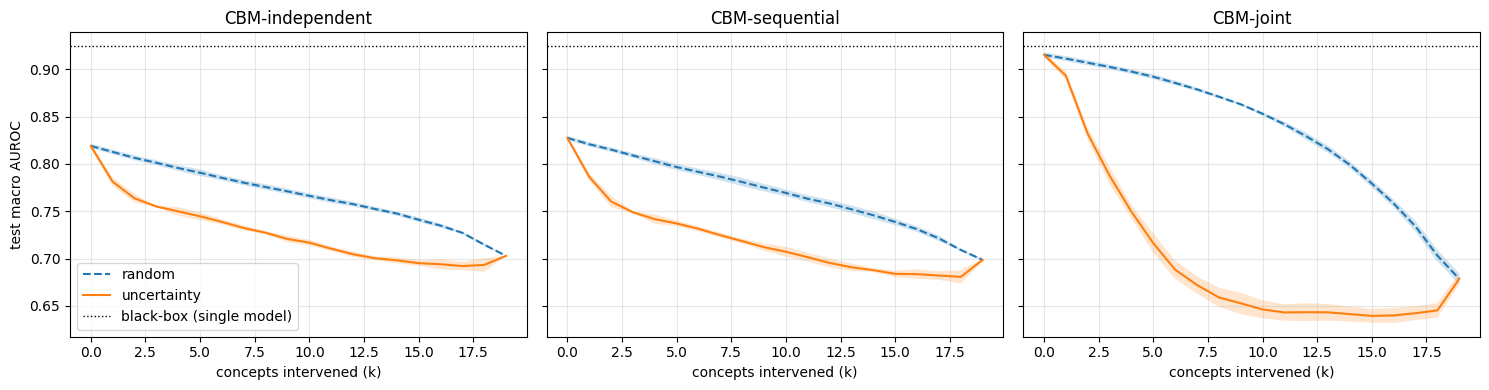

                            k=0     k=1     k=3     k=5    k=19
independent/random       0.8190  0.8127  0.8012  0.7907  0.7029
independent/uncertainty  0.8190  0.7812  0.7551  0.7447  0.7029
sequential/random        0.8274  0.8208  0.8089  0.7967  0.6986
sequential/uncertainty   0.8274  0.7863  0.7489  0.7371  0.6986
joint/random             0.9152  0.9112  0.9024  0.8921  0.6787
joint/uncertainty        0.9152  0.8931  0.7876  0.7163  0.6787


In [11]:
ks = np.arange(K + 1)
rng = np.random.default_rng(0)
rows_idx = np.arange(len(cte))[:, None]

def intervene(cp, order, k):
    c = cp.copy()
    if k:
        sel = order[:, :k]
        c[rows_idx, sel] = cte[rows_idx, sel]
    return c

curves = {}
for v in store:
    for strat in ["random", "uncertainty"]:
        per_seed = []
        for h, cp in zip(store[v]["heads"], store[v]["cp_te"]):
            orders = ([np.argsort(rng.random(cp.shape), axis=1) for _ in range(5)] if strat == "random"
                      else [np.argsort(np.abs(cp - 0.5), axis=1)])
            per_seed.append([np.mean([macro_auc(yte, head_probs(h, intervene(cp, o, k))) for o in orders]) for k in ks])
        curves[(v, strat)] = np.array(per_seed)

bb_single = per_class["black-box"].mean(1).mean()
fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
for ax, v in zip(axes, store):
    for strat, ls in [("random", "--"), ("uncertainty", "-")]:
        m, s_ = curves[(v, strat)].mean(0), curves[(v, strat)].std(0)
        ax.plot(ks, m, ls, label=strat); ax.fill_between(ks, m - s_, m + s_, alpha=0.2)
    ax.axhline(bb_single, color="k", lw=1, ls=":", label="black-box (single model)")
    ax.set_title(f"CBM-{v}"); ax.set_xlabel("concepts intervened (k)"); ax.grid(alpha=0.3)
axes[0].set_ylabel("test macro AUROC"); axes[0].legend()
plt.tight_layout(); plt.savefig(OUT / "fig2_interventions.png", dpi=150); plt.show()

summary = pd.DataFrame({f"{v}/{s}": {f"k={k}": round(curves[(v, s)].mean(0)[k], 4) for k in [0, 1, 3, 5, K]}
                        for (v, s) in curves}).T
print(summary)
summary.to_csv(OUT / "table3_interventions.csv")

## 9b. Why do interventions hurt? Disentangling annotation incompleteness (H1) from soft-probability information (H2)
- **Binarized predictions:** if AUROC drops sharply when predicted concepts are thresholded at 0.5, task information lives in the soft values (H2).
- **Rhythm-only interventions:** rhythm annotations are near-complete (96.5% coverage). If correcting them does not hurt, the problem is specific to form annotations (H1).
- **Form interventions only on form-annotated records:** if correcting form concepts hurts on all records but not on records that actually carry form annotations, the harm comes from missing annotations (H1).

In [12]:
has_form_te = L["has_form"][idx["test"]]
form_idx = [k for k, t in enumerate(CTYPE) if t == "form"]
rhy_idx = [k for k, t in enumerate(CTYPE) if t == "rhythm"]
print(f"test records with form annotation: {has_form_te.sum()} / {len(has_form_te)}")

def set_true(cp, cols, rows=None):
    c = cp.copy(); m = np.ones(len(c), bool) if rows is None else rows
    c[np.ix_(m, cols)] = cte[np.ix_(m, cols)]
    return c

rows = []
for v in store:
    for h, cp in zip(store[v]["heads"], store[v]["cp_te"]):
        rows.append({
            "variant": v,
            "a) predicted (soft)": macro_auc(yte, head_probs(h, cp)),
            "b) predicted (binarized @0.5)": macro_auc(yte, head_probs(h, (cp > 0.5).astype(np.float32))),
            "c) true rhythm only": macro_auc(yte, head_probs(h, set_true(cp, rhy_idx))),
            "d) true form, all records": macro_auc(yte, head_probs(h, set_true(cp, form_idx))),
            "e) true form, only form-annotated records": macro_auc(yte, head_probs(h, set_true(cp, form_idx, has_form_te))),
            "f) all concepts true": macro_auc(yte, head_probs(h, cte)),
        })
diag = pd.DataFrame(rows).groupby("variant").mean().round(4).T
print(diag)
diag.to_csv(OUT / "table4_intervention_diagnosis.csv")

test records with form annotation: 707 / 2158
variant                                    independent   joint  sequential
a) predicted (soft)                             0.8190  0.9152      0.8274
b) predicted (binarized @0.5)                   0.6473  0.8053      0.6468
c) true rhythm only                             0.8076  0.8857      0.8142
d) true form, all records                       0.7533  0.8479      0.7452
e) true form, only form-annotated records       0.8153  0.8910      0.8173
f) all concepts true                            0.7029  0.6787      0.6986


## 9c. Control for (e) and a leakage-free "hard" CBM
1. **Control:** correct form concepts on the same number of records (707), sampled from records *without* form annotation. If this hurts much more than (e), the harm comes from missing annotations (H1).
2. **Hard sequential CBM:** task head trained on *binarized* predicted concepts, removing the soft-probability channel (H2). Expected: lower accuracy but restored intervenability.

             Δ e) form-annotated (n=707)  Δ e') non-annotated, random (n=707)
variant                                                                      
independent                      -0.0037                              -0.0389
joint                            -0.0242                              -0.0187
sequential                       -0.0101                              -0.0453 



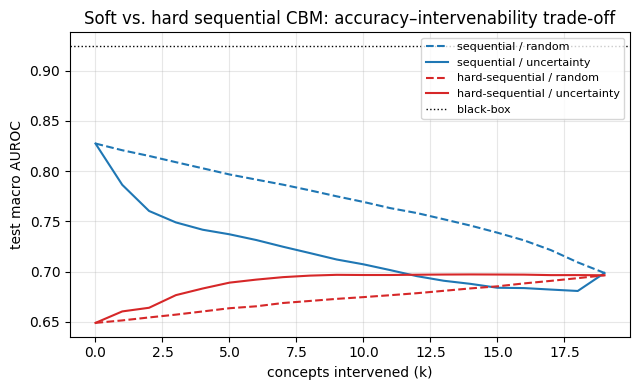

                                k=0     k=1     k=3     k=5    k=19
sequential/random            0.8274  0.8208  0.8089  0.7967  0.6986
sequential/uncertainty       0.8274  0.7863  0.7489  0.7371  0.6986
hard-sequential/random       0.6490  0.6514  0.6572  0.6636  0.6964
hard-sequential/uncertainty  0.6490  0.6604  0.6766  0.6890  0.6964


In [13]:
# 1) Control for (e)
rng_c = np.random.default_rng(0)
ctrl = np.zeros(len(cte), bool)
ctrl[rng_c.choice(np.where(~has_form_te)[0], has_form_te.sum(), replace=False)] = True
rows = []
for v in store:
    for h, cp in zip(store[v]["heads"], store[v]["cp_te"]):
        base = macro_auc(yte, head_probs(h, cp))
        rows.append({"variant": v,
                     "Δ e) form-annotated (n=707)": macro_auc(yte, head_probs(h, set_true(cp, form_idx, has_form_te))) - base,
                     "Δ e') non-annotated, random (n=707)": macro_auc(yte, head_probs(h, set_true(cp, form_idx, ctrl))) - base})
print(pd.DataFrame(rows).groupby("variant").mean().round(4), "\n")

# 2) Hard sequential CBM (reuses the trained concept models; only the head is refit)
hard_heads = []
for s in SEEDS:
    g = CBM(K).to(DEVICE); g.load_state_dict(torch.load(OUT / f"cbm_concept_seed{s}.pt", map_location=DEVICE))
    cp_tr = predict_concepts(g, Xtr); del g
    hard_heads.append(fit_head((cp_tr > 0.5).astype(np.float32), ytr, s).cpu())
hard_cp = [(cp > 0.5).astype(np.float32) for cp in store["sequential"]["cp_te"]]
soft_cp = store["sequential"]["cp_te"]

def curve(h, c_vals, c_soft, strat):
    orders = ([np.argsort(rng.random(c_soft.shape), axis=1) for _ in range(5)] if strat == "random"
              else [np.argsort(np.abs(c_soft - 0.5), axis=1)])
    return [np.mean([macro_auc(yte, head_probs(h, intervene(c_vals, o, k))) for o in orders]) for k in ks]

for strat in ["random", "uncertainty"]:
    curves[("hard-sequential", strat)] = np.array([curve(h, hc, sc, strat) for h, hc, sc in zip(hard_heads, hard_cp, soft_cp)])

fig, ax = plt.subplots(figsize=(6.5, 4))
for v, col in [("sequential", "tab:blue"), ("hard-sequential", "tab:red")]:
    for strat, ls in [("random", "--"), ("uncertainty", "-")]:
        m = curves[(v, strat)].mean(0)
        ax.plot(ks, m, ls, color=col, label=f"{v} / {strat}")
ax.axhline(bb_single, color="k", lw=1, ls=":", label="black-box")
ax.set_xlabel("concepts intervened (k)"); ax.set_ylabel("test macro AUROC"); ax.grid(alpha=0.3); ax.legend(fontsize=8)
ax.set_title("Soft vs. hard sequential CBM: accuracy–intervenability trade-off")
plt.tight_layout(); plt.savefig(OUT / "fig4_soft_vs_hard.png", dpi=150); plt.show()
print(pd.DataFrame({f"{v}/{s}": {f"k={k}": round(curves[(v, s)].mean(0)[k], 4) for k in [0, 1, 3, 5, K]}
                    for (v, s) in curves if "sequential" in v}).T)

## 10. E3 — Interpretability: concept → diagnosis weights
Weights of the linear task head of the independent CBM (mean over seeds). Inputs are concept probabilities in [0, 1], so weights are directly comparable: red = evidence for the class, blue = evidence against. To be checked against clinical knowledge and the EDA heatmap (Figure 1).

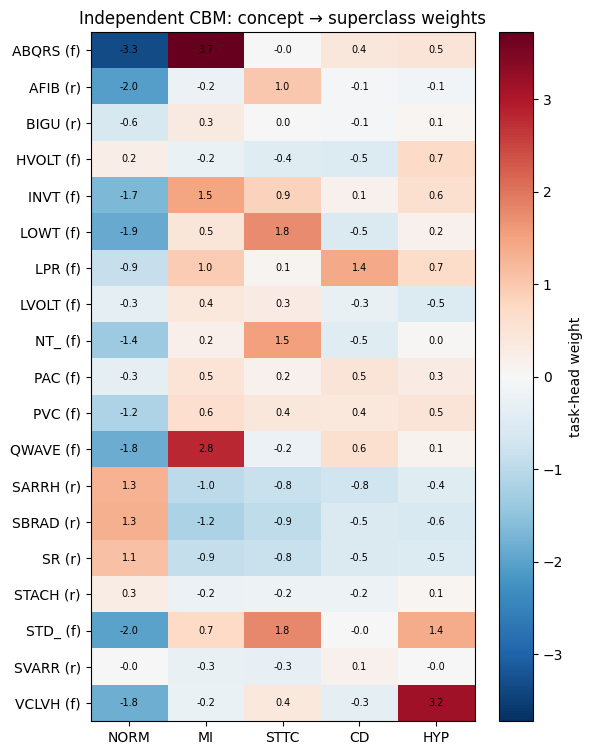

In [14]:
W = np.mean([h.weight.detach().numpy() for h in store["independent"]["heads"]], axis=0).T  # (K, 5)
vmax = np.abs(W).max()
fig, ax = plt.subplots(figsize=(6, 0.35 * K + 1))
im = ax.imshow(W, cmap="RdBu_r", vmin=-vmax, vmax=vmax, aspect="auto")
ax.set_xticks(range(len(SUPER)), SUPER); ax.set_yticks(range(K), [f"{c} ({t[0]})" for c, t in zip(CONCEPTS, CTYPE)])
for i in range(K):
    for j in range(len(SUPER)):
        ax.text(j, i, f"{W[i, j]:.1f}", ha="center", va="center", fontsize=7)
fig.colorbar(im, label="task-head weight")
ax.set_title("Independent CBM: concept → superclass weights")
plt.tight_layout(); plt.savefig(OUT / "fig3_concept_weights.png", dpi=150); plt.show()
pd.DataFrame(W, index=CONCEPTS, columns=SUPER).round(3).to_csv(OUT / "concept_weights_independent.csv")

## 11. Experiment A — Joint CBM: sweeping the concept-loss weight λ
λ controls how strongly the joint model is forced to keep its concepts faithful (loss = L_y + λ·L_c).
We train λ ∈ {0.1, 1, 10, 100} with 3 seeds each and measure, on the test fold:
task AUROC with predicted concepts (soft and binarized), after correcting the 5 most uncertain concepts,
and with all concepts annotated; plus mean concept AUROC and CD AUROC.
Expected: higher λ → more faithful concepts and less harm from interventions, at a cost in task accuracy.

λ=0.1 seed 0 | task 0.9225 | concepts 0.6318 | k5-unc 0.8347 | all-annotated 0.5298 | 2.1 min
λ=0.1 seed 1 | task 0.9222 | concepts 0.6451 | k5-unc 0.8432 | all-annotated 0.5591 | 2.0 min
λ=0.1 seed 2 | task 0.9181 | concepts 0.5934 | k5-unc 0.8407 | all-annotated 0.5612 | 1.5 min
λ=1 seed 0 | task 0.9185 | concepts 0.8864 | k5-unc 0.7136 | all-annotated 0.6821 | 2.4 min
λ=1 seed 1 | task 0.9120 | concepts 0.8626 | k5-unc 0.6971 | all-annotated 0.6703 | 1.9 min
λ=1 seed 2 | task 0.9175 | concepts 0.8833 | k5-unc 0.7226 | all-annotated 0.6733 | 2.1 min


λ=10 seed 0 | task 0.8555 | concepts 0.9263 | k5-unc 0.7333 | all-annotated 0.7017 | 2.4 min


λ=10 seed 1 | task 0.8489 | concepts 0.9270 | k5-unc 0.7319 | all-annotated 0.6995 | 2.2 min


λ=10 seed 2 | task 0.8496 | concepts 0.9269 | k5-unc 0.7436 | all-annotated 0.7022 | 2.1 min


λ=100 seed 0 | task 0.8191 | concepts 0.9255 | k5-unc 0.7409 | all-annotated 0.6989 | 1.8 min


λ=100 seed 1 | task 0.8228 | concepts 0.9280 | k5-unc 0.7339 | all-annotated 0.6994 | 2.0 min


λ=100 seed 2 | task 0.8212 | concepts 0.9226 | k5-unc 0.7257 | all-annotated 0.6982 | 1.4 min
        val_task  task_soft  task_binarized  task_k5_uncertainty  \
lambda                                                             
0.1       0.9237     0.9209          0.9042               0.8395   
1.0       0.9203     0.9160          0.8132               0.7111   
10.0      0.8532     0.8514          0.6984               0.7363   
100.0     0.8252     0.8210          0.6579               0.7335   

        task_all_annotated  concept_auc  auc_CD  task_soft_std  
lambda                                                          
0.1                 0.5501       0.6234  0.9202         0.0025  
1.0                 0.6752       0.8775  0.9100         0.0035  
10.0                0.7011       0.9267  0.7299         0.0036  
100.0               0.6988       0.9254  0.6937         0.0019  


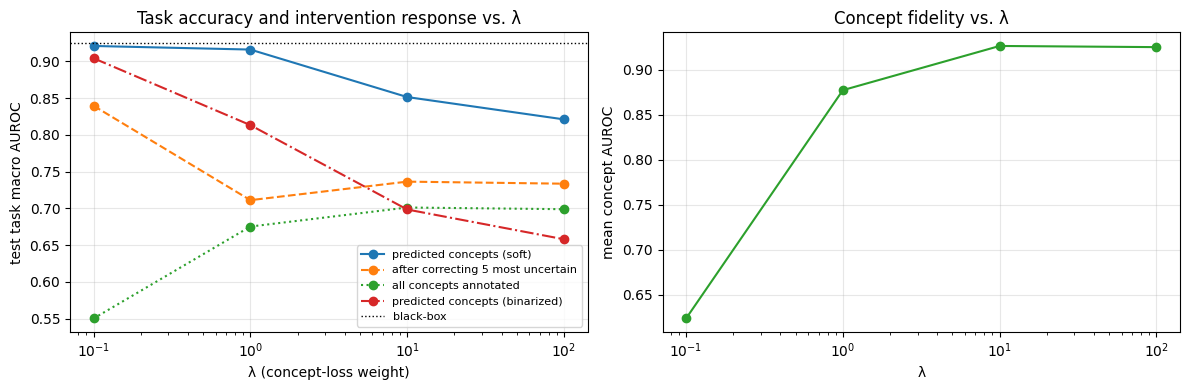

In [5]:
LAMBDAS = [0.1, 1.0, 10.0, 100.0]
SWEEP_SEEDS = [0, 1, 2]
rows_idx = np.arange(len(cte))[:, None]

def intervene(cp, order, k):
    c = cp.copy()
    if k:
        sel = order[:, :k]
        c[rows_idx, sel] = cte[rows_idx, sel]
    return c

def mean_concept_auc(cp):
    return np.mean([roc_auc_score(cte[:, k], cp[:, k]) for k in range(K) if 0 < cte[:, k].sum() < len(cte)])

sweep = []
for lam in LAMBDAS:
    for s in SWEEP_SEEDS:
        t0 = time.time()
        m, best_val, hist = train_cbm(s, "joint", lam=lam)
        cp = predict_concepts(m, Xte); h = m.task_head
        unc = np.argsort(np.abs(cp - 0.5), axis=1)
        p_soft = head_probs(h, cp)
        sweep.append({"lambda": lam, "seed": s, "val_task": best_val, "epochs": len(hist),
                      "task_soft": macro_auc(yte, p_soft),
                      "task_binarized": macro_auc(yte, head_probs(h, (cp > 0.5).astype(np.float32))),
                      "task_k5_uncertainty": macro_auc(yte, head_probs(h, intervene(cp, unc, 5))),
                      "task_all_annotated": macro_auc(yte, head_probs(h, cte)),
                      "concept_auc": mean_concept_auc(cp),
                      "auc_CD": roc_auc_score(yte[:, SUPER.index("CD")], p_soft[:, SUPER.index("CD")])})
        r = sweep[-1]
        print(f"λ={lam:g} seed {s} | task {r['task_soft']:.4f} | concepts {r['concept_auc']:.4f} | "
              f"k5-unc {r['task_k5_uncertainty']:.4f} | all-annotated {r['task_all_annotated']:.4f} | {(time.time() - t0) / 60:.1f} min")
        torch.save(m.state_dict(), OUT / f"cbm_joint_lam{lam:g}_seed{s}.pt")
        del m; torch.cuda.empty_cache()

sw = pd.DataFrame(sweep)
sw.to_csv(OUT / "table5_lambda_sweep_raw.csv", index=False)
summ = sw.drop(columns=["seed", "epochs"]).groupby("lambda").mean().round(4)
summ["task_soft_std"] = sw.groupby("lambda")["task_soft"].std().round(4)
print(summ)
summ.to_csv(OUT / "table5_lambda_sweep.csv")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
lam_x = summ.index.values
for col, lab, ls in [("task_soft", "predicted concepts (soft)", "-"),
                     ("task_k5_uncertainty", "after correcting 5 most uncertain", "--"),
                     ("task_all_annotated", "all concepts annotated", ":"),
                     ("task_binarized", "predicted concepts (binarized)", "-.")]:
    axes[0].plot(lam_x, summ[col], ls, marker="o", label=lab)
axes[0].axhline(bb_single if "bb_single" in globals() else 0.9243, color="k", lw=1, ls=":", label="black-box")
axes[0].set_xscale("log"); axes[0].set_xlabel("λ (concept-loss weight)"); axes[0].set_ylabel("test task macro AUROC")
axes[0].legend(fontsize=8); axes[0].grid(alpha=0.3); axes[0].set_title("Task accuracy and intervention response vs. λ")
axes[1].plot(lam_x, summ["concept_auc"], marker="o", color="tab:green")
axes[1].set_xscale("log"); axes[1].set_xlabel("λ"); axes[1].set_ylabel("mean concept AUROC"); axes[1].grid(alpha=0.3)
axes[1].set_title("Concept fidelity vs. λ")
plt.tight_layout(); plt.savefig(OUT / "fig5_lambda_sweep.png", dpi=150); plt.show()

### 12-pre. Restore concept models (seeds 0–2) if the session was reset
Training is seeded and reproducible, so retraining yields the same concept models used in section 6.

In [7]:
for s in [0, 1, 2]:
    path = OUT / f"cbm_concept_seed{s}.pt"
    if path.exists():
        print(f"seed {s}: found"); continue
    t0 = time.time()
    g, best_c, _ = train_cbm(s, "concept")
    torch.save(g.state_dict(), path)
    print(f"seed {s}: concept val AUROC {best_c:.4f} (section 6: ~0.937) | {(time.time() - t0) / 60:.1f} min")
    del g; torch.cuda.empty_cache()

seed 0: concept val AUROC 0.9380 (section 6: ~0.937) | 2.3 min
seed 1: concept val AUROC 0.9374 (section 6: ~0.937) | 2.1 min
seed 2: concept val AUROC 0.9347 (section 6: ~0.937) | 1.7 min


## 12. Experiment B — Hard CBM with a controlled residual channel
Task head = linear over [hard concepts (binarized predictions of the trained concept model), residual r],
where r = a d-dimensional projection of the black-box encoder features (the information the concepts miss).
Leakage controls: small d, residual dropout p (forces reliance on concepts), and a decorrelation penalty β
between r and the concepts (prevents r from duplicating them). Grid: d ∈ {0, 2, 8, 32} × p ∈ {0, 0.5} × β ∈ {0, 1}, 3 seeds.
**Selection rule, fixed in advance, validation only:** highest validation AUROC among configurations whose
validation AUROC does not decrease when concepts are corrected (5 most uncertain, and all).

In [8]:
import glob as _glob

def find_file(name):
    for root in [OUT, Path("/kaggle/input")]:
        hits = sorted(_glob.glob(str(root / "**" / name), recursive=True))
        if hits:
            return Path(hits[0])
    raise FileNotFoundError(f"{name} not found: re-run cell 6 in this session, or add notebook 03's output as input")

class BlackBox(nn.Module):  # same definition as notebook 02, to load its weights
    def __init__(self, n_out=5, p_drop=0.3):
        super().__init__()
        self.enc = Encoder()
        self.head = nn.Sequential(nn.Dropout(p_drop), nn.Linear(self.enc.out_dim, n_out))
    def forward(self, x):
        return self.head(self.enc(x))

@torch.no_grad()
def window_features(enc, Xt, bs=512):
    """Encoder features averaged over sliding 2.5 s windows, shape (N, 512)."""
    enc.eval(); out = []
    starts = range(0, Xt.shape[-1] - WIN + 1, STRIDE)
    for i in range(0, len(Xt), bs):
        xb = Xt[i:i + bs].to(DEVICE)
        with torch.autocast("cuda", enabled=AMP):
            fs = [enc(xb[:, :, s:s + WIN]).float() for s in starts]
        out.append(torch.stack(fs).mean(0).cpu())
    return torch.cat(out).numpy()

B_SEEDS = [0, 1, 2]
SPLITS = [("train", Xtr), ("val", Xva), ("test", Xte)]
feat = {}
for s in B_SEEDS:
    g = CBM(K).to(DEVICE); g.load_state_dict(torch.load(find_file(f"cbm_concept_seed{s}.pt"), map_location=DEVICE))
    bb = BlackBox().to(DEVICE); bb.load_state_dict(torch.load(find_file(f"blackbox_crop_seed{s}.pt"), map_location=DEVICE))
    cps = {k: predict_concepts(g, X_) for k, X_ in SPLITS}
    phis = {k: window_features(bb.enc, X_) for k, X_ in SPLITS}
    mu_f, sd_f = phis["train"].mean(0), phis["train"].std(0) + 1e-6   # train-only statistics
    feat[s] = {"cp": cps, "phi": {k: (v - mu_f) / sd_f for k, v in phis.items()}}
    del g, bb; torch.cuda.empty_cache()
    print(f"seed {s}: features ready")

seed 0: features ready
seed 1: features ready
seed 2: features ready


In [9]:
if "summ" not in globals():
    try:
        summ = pd.read_csv(find_file("table5_lambda_sweep.csv"), index_col=0)
    except FileNotFoundError:
        print("λ-sweep table not found; the frontier plot will omit those points")

λ-sweep table not found; the frontier plot will omit those points


### 12b. Hybrid model, training and evaluation

In [11]:
class Hybrid(nn.Module):
    def __init__(self, d, p_res):
        super().__init__()
        self.d, self.p_res = d, p_res
        self.proj = nn.Linear(512, d) if d > 0 else None
        self.head = nn.Linear(K + d, len(SUPER))
    def forward(self, c, phi, use_res=True):
        r = self.proj(phi) if self.d > 0 else phi[:, :0]
        r_used = r if use_res else torch.zeros_like(r)
        if self.training and self.p_res > 0 and self.d > 0:   # residual dropout (whole vector per record)
            keep = (torch.rand(r.shape[0], 1, device=r.device) > self.p_res).float()
            r_used = r * keep / (1 - self.p_res)
        return self.head(torch.cat([c, r_used], 1)), r

def decor(r, c):
    """Mean squared cross-correlation between residual dims and concepts."""
    if r.shape[1] == 0:
        return r.sum() * 0
    rz = (r - r.mean(0)) / (r.std(0) + 1e-6); cz = (c - c.mean(0)) / (c.std(0) + 1e-6)
    return ((rz.T @ cz) / len(r)).pow(2).mean()

def to_t(a):
    return torch.as_tensor(a, dtype=torch.float32, device=DEVICE)

@torch.no_grad()
def hybrid_probs(model, c, phi, use_res=True):
    model.eval()
    return torch.sigmoid(model(to_t(c), to_t(phi), use_res)[0]).cpu().numpy()

def train_hybrid(s, d, p_res, beta, epochs=150, bs=1024, lr=1e-3, patience=20):
    set_seed(s); F_ = feat[s]
    Ct = to_t((F_["cp"]["train"] > 0.5).astype(np.float32)); Pt = to_t(F_["phi"]["train"]); Yt = to_t(ytr)
    cva_h = (F_["cp"]["val"] > 0.5).astype(np.float32)
    model = Hybrid(d, p_res).to(DEVICE)
    opt = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=1e-4)
    best, best_state, bad = -1.0, None, 0
    for ep in range(epochs):
        model.train(); perm = torch.randperm(len(Ct), device=DEVICE)
        for i in range(0, len(Ct), bs):
            b = perm[i:i + bs]
            logits, r = model(Ct[b], Pt[b])
            loss = F.binary_cross_entropy_with_logits(logits, Yt[b]) + beta * decor(r, Ct[b])
            opt.zero_grad(); loss.backward(); opt.step()
        va = macro_auc(yva, hybrid_probs(model, cva_h, F_["phi"]["val"]))
        if va > best:
            best, bad = va, 0
            best_state = {k: v.clone() for k, v in model.state_dict().items()}
        else:
            bad += 1
            if bad >= patience:
                break
    model.load_state_dict(best_state)
    return model

def evaluate_hybrid(model, s):
    F_ = feat[s]; out = {}
    for split, cann, y in [("val", cva, yva), ("test", cte, yte)]:
        cp, phi = F_["cp"][split], F_["phi"][split]
        ch = (cp > 0.5).astype(np.float32)
        rws = np.arange(len(ch))[:, None]; sel = np.argsort(np.abs(cp - 0.5), axis=1)[:, :5]
        c5 = ch.copy(); c5[rws, sel] = cann[rws, sel]
        p0 = hybrid_probs(model, ch, phi)
        out[f"{split}_k0"] = macro_auc(y, p0)
        out[f"{split}_k5"] = macro_auc(y, hybrid_probs(model, c5, phi))
        out[f"{split}_all"] = macro_auc(y, hybrid_probs(model, cann, phi))
        out[f"{split}_concepts_only"] = macro_auc(y, hybrid_probs(model, ch, phi, use_res=False))
        if split == "test":
            out["test_CD"] = roc_auc_score(y[:, SUPER.index("CD")], p0[:, SUPER.index("CD")])
    return out

### 12c. Grid, selection and accuracy–intervenability frontier

d= 0 p=0.0 β=0 | test k0 0.6446 | k5 0.6852 | all 0.6917 | concepts-only 0.6446 | CD 0.5731 | 10s
d= 2 p=0.0 β=0 | test k0 0.8929 | k5 0.9065 | all 0.9081 | concepts-only 0.5561 | CD 0.9062 | 18s
d= 2 p=0.0 β=1 | test k0 0.8909 | k5 0.9052 | all 0.9068 | concepts-only 0.5638 | CD 0.9121 | 18s
d= 2 p=0.5 β=0 | test k0 0.8886 | k5 0.9036 | all 0.9051 | concepts-only 0.6112 | CD 0.9033 | 11s
d= 2 p=0.5 β=1 | test k0 0.8873 | k5 0.9030 | all 0.9042 | concepts-only 0.6148 | CD 0.9161 | 12s
d= 8 p=0.0 β=0 | test k0 0.9234 | k5 0.9234 | all 0.9236 | concepts-only 0.5023 | CD 0.9181 | 3s
d= 8 p=0.0 β=1 | test k0 0.9228 | k5 0.9227 | all 0.9228 | concepts-only 0.5038 | CD 0.9194 | 3s
d= 8 p=0.5 β=0 | test k0 0.9238 | k5 0.9276 | all 0.9283 | concepts-only 0.5883 | CD 0.9193 | 7s
d= 8 p=0.5 β=1 | test k0 0.9237 | k5 0.9275 | all 0.9282 | concepts-only 0.5874 | CD 0.9189 | 7s
d=32 p=0.0 β=0 | test k0 0.9254 | k5 0.9261 | all 0.9261 | concepts-only 0.5096 | CD 0.9202 | 8s
d=32 p=0.0 β=1 | test k0 

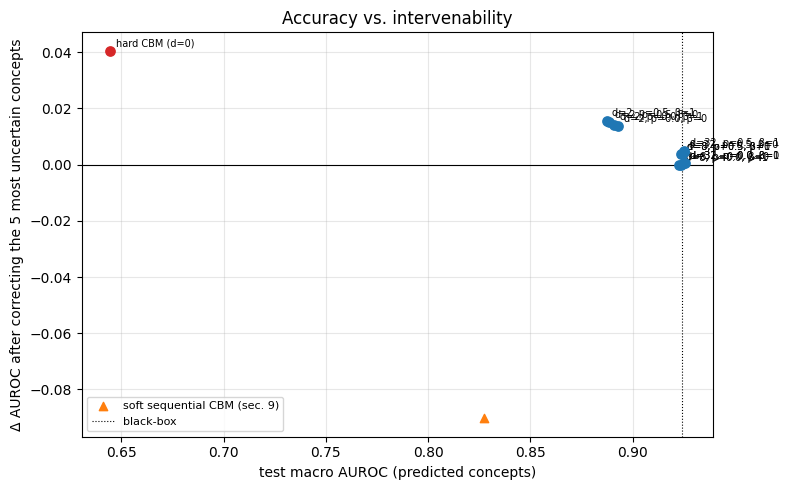

In [12]:
GRID = [(0, 0.0, 0.0)] + [(d, p, b) for d in (2, 8, 32) for p in (0.0, 0.5) for b in (0.0, 1.0)]
res_b = []
for (d, p, b) in GRID:
    t0 = time.time()
    for s in B_SEEDS:
        m = train_hybrid(s, d, p, b)
        res_b.append({"d": d, "p_res": p, "beta": b, "seed": s, **evaluate_hybrid(m, s)})
    r = pd.DataFrame(res_b[-len(B_SEEDS):]).mean(numeric_only=True)
    print(f"d={d:2d} p={p} β={b:g} | test k0 {r.test_k0:.4f} | k5 {r.test_k5:.4f} | all {r.test_all:.4f} | "
          f"concepts-only {r.test_concepts_only:.4f} | CD {r.test_CD:.4f} | {time.time() - t0:.0f}s")

Bdf = pd.DataFrame(res_b); Bdf.to_csv(OUT / "table6_hybrid_raw.csv", index=False)
S = Bdf.drop(columns="seed").groupby(["d", "p_res", "beta"]).mean()
S["test_gain_k5"] = S.test_k5 - S.test_k0
S["test_gain_all"] = S.test_all - S.test_k0
cols = ["test_k0", "test_k5", "test_all", "test_gain_k5", "test_gain_all", "test_concepts_only", "test_CD"]
print("\n", S[cols].round(4))
S.round(4).to_csv(OUT / "table6_hybrid.csv")

# Selection rule fixed in advance (validation only)
ok = S[(S.val_k5 >= S.val_k0) & (S.val_all >= S.val_k0)]
best_cfg = ok.val_k0.idxmax() if len(ok) else None
print("\nSelected by validation rule (d, p, β):", best_cfg)
if best_cfg is not None:
    print(S.loc[best_cfg, cols].round(4))

fig, ax = plt.subplots(figsize=(8, 5))
for (d, p, b), r in S.iterrows():
    ax.scatter(r.test_k0, r.test_gain_k5, color="tab:red" if d == 0 else "tab:blue", s=45, zorder=3)
    ax.annotate("hard CBM (d=0)" if d == 0 else f"d={d}, p={p}, β={b:g}", (r.test_k0, r.test_gain_k5),
                fontsize=7, xytext=(4, 3), textcoords="offset points")
if "summ" in globals():
    ax.scatter(summ.task_soft, summ.task_k5_uncertainty - summ.task_soft, marker="s", color="tab:gray", label="joint CBM, λ sweep")
ax.scatter([0.8274], [0.7371 - 0.8274], marker="^", color="tab:orange", label="soft sequential CBM (sec. 9)")
ax.axhline(0, color="k", lw=0.8); ax.axvline(0.9243, color="k", lw=0.8, ls=":", label="black-box")
ax.set_xlabel("test macro AUROC (predicted concepts)")
ax.set_ylabel("Δ AUROC after correcting the 5 most uncertain concepts")
ax.set_title("Accuracy vs. intervenability"); ax.grid(alpha=0.3); ax.legend(fontsize=8, loc="lower left")
plt.tight_layout(); plt.savefig(OUT / "fig6_frontier.png", dpi=150); plt.show()

### 12d. Selected hybrid: significance of the intervention gain, concept share of the decision, final frontier figure
- Paired bootstrap of the ensemble AUROC change after correcting the 5 most uncertain concepts.
- **Concept share:** per class, the fraction of logit variance contributed by the concept term (W_c·c) vs. the residual term (W_r·r). Measures how much of the decision the concepts actually carry.

   seed  delta_k5  concept_share_NORM  concept_share_MI  concept_share_STTC  \
0     0    0.0049              0.0169            0.0105              0.0189   
1     1    0.0051              0.0346            0.0224              0.0396   
2     2    0.0050              0.0157            0.0104              0.0194   

   concept_share_CD  concept_share_HYP  
0            0.0008             0.0093  
1            0.0010             0.0115  
2            0.0009             0.0107  

       delta_k5  concept_share_NORM  concept_share_MI  concept_share_STTC  \
mean    0.0050              0.0224            0.0144              0.0260   
std     0.0001              0.0106            0.0069              0.0118   

      concept_share_CD  concept_share_HYP  
mean            0.0009             0.0105  
std             0.0001             0.0011  

Ensemble Δ AUROC after correcting 5 concepts: +0.0051  (95% CI +0.0034 to +0.0067)


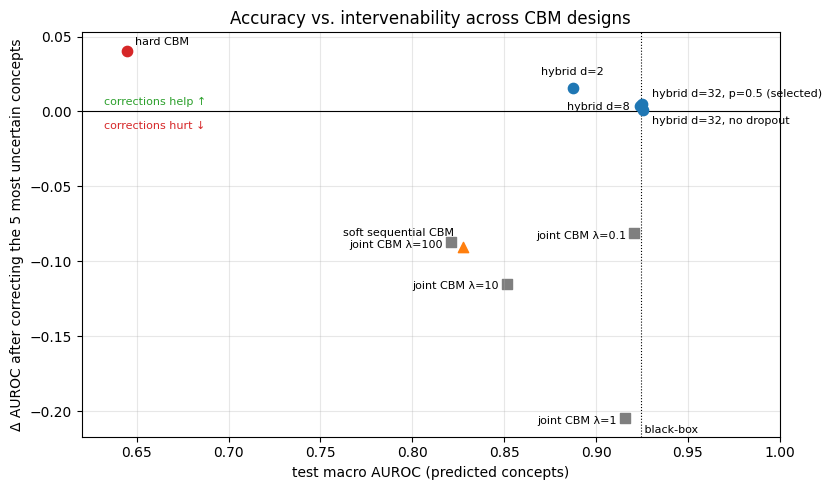

In [14]:
d_, p_, b_ = int(best_cfg[0]), float(best_cfg[1]), float(best_cfg[2])
rows, probs0, probs5 = [], [], []
for s in B_SEEDS:
    m = train_hybrid(s, d_, p_, b_)                      # seeded: identical to the grid run
    cp, phi = feat[s]["cp"]["test"], feat[s]["phi"]["test"]
    ch = (cp > 0.5).astype(np.float32); rws = np.arange(len(ch))[:, None]
    sel = np.argsort(np.abs(cp - 0.5), axis=1)[:, :5]
    c5 = ch.copy(); c5[rws, sel] = cte[rws, sel]
    p0, p5 = hybrid_probs(m, ch, phi), hybrid_probs(m, c5, phi)
    probs0.append(p0); probs5.append(p5)
    with torch.no_grad():
        Wc = m.head.weight[:, :K].cpu().numpy(); Wr = m.head.weight[:, K:].cpu().numpy()
        r = m.proj(to_t(phi)).cpu().numpy()
    lc, lr = ch @ Wc.T, r @ Wr.T
    share = lc.var(0) / (lc.var(0) + lr.var(0))
    rows.append({"seed": s, "delta_k5": macro_auc(yte, p5) - macro_auc(yte, p0),
                 **{f"concept_share_{c}": v for c, v in zip(SUPER, share)}})
sig = pd.DataFrame(rows)
print(sig.round(4)); print("\n", sig.drop(columns="seed").agg(["mean", "std"]).round(4))
dm, lo, hi = paired_delta(yte, np.mean(probs5, 0), np.mean(probs0, 0))
print(f"\nEnsemble Δ AUROC after correcting 5 concepts: {dm:+.4f}  (95% CI {lo:+.4f} to {hi:+.4f})")
sig.to_csv(OUT / "table7_hybrid_significance.csv", index=False)

# Clean frontier figure (representative points only)
lam_pts = {0.1: (0.9209, 0.8395), 1: (0.9160, 0.7111), 10: (0.8514, 0.7363), 100: (0.8210, 0.7335)}  # section 11 output
fig, ax = plt.subplots(figsize=(8.5, 5))
ax.axhline(0, color="k", lw=0.8); ax.axvline(0.9243, color="k", lw=0.8, ls=":")
for lam, (a, k5) in lam_pts.items():
    ax.scatter(a, k5 - a, marker="s", color="tab:gray", s=45)
    ax.annotate(f"joint CBM λ={lam:g}", (a, k5 - a), fontsize=8, xytext=(-6, -4), textcoords="offset points", ha="right")
ax.scatter(0.8274, 0.7371 - 0.8274, marker="^", color="tab:orange", s=55)
ax.annotate("soft sequential CBM", (0.8274, 0.7371 - 0.8274), fontsize=8, xytext=(-6, 8) if lam == 100 else (-6, -4), textcoords="offset points", ha="right")
labels = {(0, 0.0, 0.0): ("hard CBM", (6, 4), "left"),
          (2, 0.5, 1.0): ("hybrid d=2", (0, 9), "center"),
          (8, 0.5, 1.0): ("hybrid d=8", (-7, -3), "right"),
          (32, 0.5, 1.0): ("hybrid d=32, p=0.5 (selected)", (7, 5), "left"),
          (32, 0.0, 0.0): ("hybrid d=32, no dropout", (7, -10), "left")}
for key, (lab, off, ha) in labels.items():
    r = S.loc[key]
    ax.scatter(r.test_k0, r.test_gain_k5, color="tab:red" if key[0] == 0 else "tab:blue", s=55, zorder=3)
    ax.annotate(lab, (r.test_k0, r.test_gain_k5), fontsize=8, xytext=off, textcoords="offset points", ha=ha)
ax.text(0.632, 0.004, "corrections help ↑", fontsize=8, color="tab:green")
ax.text(0.632, -0.012, "corrections hurt ↓", fontsize=8, color="tab:red")
ax.text(0.9243, -0.215, " black-box", fontsize=8)
ax.set_xlim(0.62, 1.0); ax.set_xlabel("test macro AUROC (predicted concepts)")
ax.set_ylabel("Δ AUROC after correcting the 5 most uncertain concepts")
ax.set_title("Accuracy vs. intervenability across CBM designs"); ax.grid(alpha=0.3)
plt.tight_layout(); plt.savefig(OUT / "fig6_frontier.png", dpi=150); plt.show()